# Motor-imagery model comparisons

This notebook compares CSP plus LDA, a Riemannian baseline, EEGNet, and filter-bank CSP on the available screened recordings. Read the executed loading and QC outputs for the current trial counts. Results are exploratory because these data and model settings have already informed development.

In [2]:
from pathlib import Path
import sys

import mne
import numpy as np
import pandas as pd

import torch

from braindecode import EEGClassifier
from braindecode.models import EEGNet

from mne.decoding import CSP, get_spatial_filter_from_estimator

from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace


from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.metrics import balanced_accuracy_score

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "clean.py").is_file()),
)
sys.path.insert(0, str(PROJECT_ROOT))
from loader import get_files
from clean import load_dataset, save_qc

mne.set_log_level("WARNING")

### Load screened imagery trials

`load_dataset()` applies the fixed channel and trial QC rules in `clean.py`. The trial QC table keeps one row per original trial, including rejection reasons. This cell also updates the reports in `data/processed/qc`.

In [4]:
files = get_files()
dataset = load_dataset(files)
epochs = dataset.epochs
qc_summary = save_qc(dataset, files)

print(f"Kept {len(epochs)} of {len(dataset.trial_qc)} trials")
print(f"Interpolated channel/run pairs: {dataset.channel_qc['interpolated'].sum()}")
print(qc_summary.loc[qc_summary["review_required"]].to_string(index=False))

/Users/trentonpham/Code/eeg-motor-imagery/clean.py:238: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  mne.concatenate_epochs([result.epochs for result in results]),
/Users/trentonpham/Code/eeg-motor-imagery/clean.py:238: RuntimeWarning: One of the Epochs objects to concatenate was empty.
  mne.concatenate_epochs([result.epochs for result in results]),
/Users/trentonpham/Code/eeg-motor-imagery/clean.py:238: RuntimeWarning: One of the Epochs objects to concatenate was empty.
  mne.concatenate_epochs([result.epochs for result in results]),
/Users/trentonpham/Code/eeg-motor-imagery/clean.py:238: RuntimeWarning: One of the Epochs objects to concatenate was empty.
  mne.concatenate_epochs([result.epochs for result in results]),
/Users/trentonpham/Code/eeg-motor-imagery/clean.py:238: RuntimeWarning: One of the Epochs objects to concatenate was empty.
  mne.concatenate_epochs([result.epochs for result in results]),
/Users/tr

Kept 729 of 900 trials
Interpolated channel/run pairs: 4
 subject  run  condition  total  kept  rejected  review_required
       9    4  left_hand      8     0         8             True
       9    4 right_hand      7     0         7             True
       9    8  left_hand      8     0         8             True
       9    8 right_hand      7     0         7             True
       9   12  left_hand      8     0         8             True
       9   12 right_hand      7     0         7             True
      13    4  left_hand      8     0         8             True
      13    4 right_hand      7     0         7             True
      13    8  left_hand      8     0         8             True
      13    8 right_hand      7     0         7             True
      13   12  left_hand      7     0         7             True
      13   12 right_hand      8     0         8             True
      17    8  left_hand      8     0         8             True
      17    8 right_hand      7  

## Modeling

### Prepare model inputs

`X` contains screened EEG in volts, with dimensions for trials, channels, and time samples. `y` contains the integer labels 1 and 2. `subjects` and `runs` identify the groups used to keep validation trials separate from training trials.

In [5]:
X = epochs.get_data(copy=True)
y = epochs.events[:, -1]

subjects = epochs.metadata["subject"].to_numpy()
runs = epochs.metadata["run"].to_numpy()

print("EEG array:", X.shape)
print("Labels:", np.unique(y, return_counts=True))

EEG array: (729, 64, 481)
Labels: (array([1, 2]), array([364, 365]))


### Check class balance

The table below reports left-hand and right-hand trial counts after QC for each subject. The analysis does not oversample either class. Review the flagged run and condition rows from the loading cell before interpreting model results.

In [6]:
trial_table = epochs.metadata.copy()
trial_table["condition"] = np.where(
    y == 1,
    "left_hand",
    "right_hand",
)

pd.crosstab(
    trial_table["subject"],
    trial_table["condition"],
    margins=True,
)

condition,left_hand,right_hand,All
subject,,,
1,22,22,44
2,23,22,45
3,21,20,41
4,23,22,45
5,21,24,45
6,21,19,40
7,23,21,44
8,22,23,45
10,24,20,44


### Model 1: Build the CSP and LDA baseline

Common spatial patterns, or CSP, learns spatial filters from labeled training EEG and converts each trial to log-power features. The pipeline uses Ledoit-Wolf covariance regularization and shrinkage LDA. Inner subject-held-out validation selects two, four, or six CSP components using only the outer training subjects.

In [ ]:
rows = []

csp_lda = make_pipeline(
    CSP(reg="ledoit_wolf", log=True, norm_trace=False),
    LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"),
)

param_grid = {
    "csp__n_components": [2, 4, 6],
}

for train, test in LeaveOneGroupOut().split(X, y, groups=subjects):
    search = GridSearchCV(
        csp_lda,
        param_grid,
        cv=LeaveOneGroupOut(),
        scoring="balanced_accuracy",
        refit=True,
        error_score="raise",
    )
    search.fit(X[train], y[train], groups=subjects[train])

    best_model = search.best_estimator_
    predictions = best_model.predict(X[test])

    rows.append({
        "subject": int(subjects[test][0]),
        "n_components": search.best_params_["csp__n_components"],
        "balanced_accuracy": balanced_accuracy_score(y[test], predictions),
    })

results = pd.DataFrame(rows)
display(results)
print("Mean balanced accuracy:", results["balanced_accuracy"].mean())

,subject,n_components,balanced_accuracy
0,1,6,0.659091
1,2,6,0.682806
2,3,6,0.392857
3,4,4,0.500000
4,5,4,0.511905
5,6,4,0.481203
6,7,4,0.932712
7,8,6,0.600791
8,10,6,0.608333
9,11,6,0.431818


Mean balanced accuracy: 0.5982728422945814


#### Interpret held-out-subject evaluation

The outer loop tests each subject using a model fitted on the other subjects. An inner subject-held-out loop selects the CSP component count. This evaluates transfer across subjects, with whole-recording preprocessing applied separately to each recording.

Balanced accuracy gives equal weight to left-hand and right-hand recall. The 50% reference is not a significance threshold. These exploratory results do not establish performance on untouched participants.

### Historical tuning notes

These values come from earlier runs with different settings and datasets. They record development history and are not a comparison on a common evaluation set. 
#### 1) Covariance Regularization
- No covariance regularization: 0.4613
- `ledoit_wolf`: 0.4669
- `oas`: 0.4669
- `0.10`: 0.4831 (may not adjust to unfamiliar data)

#### 2) n_components
- GridSearchCV: 0.4903
- GridSearchCV + cov reg `0.20`: 0.5313 (may not adjust to unfamiliar data)

#### 3) Secure all 17 subjects:
- No changes: 0.6026
- Adjusted grid search n_components ([2, 4, 6]): 0.5856
- Cov Reg `ledoit_wolf`: 0.5983

### Model 2: Build the Riemannian baseline

In [10]:
rows = []

riemann_lda = make_pipeline(
    Covariances(estimator="lwf"),
    TangentSpace(metric="riemann", tsupdate=False),
    LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
)

for train, test in LeaveOneGroupOut().split(X, y, groups=subjects):
    riemann_lda.fit(X[train], y[train])
    predictions = riemann_lda.predict(X[test])
    
    rows.append({
        "subject": int(subjects[test][0]),
        "balanced_accuracy": balanced_accuracy_score(y[test], predictions),
    })
    
results = pd.DataFrame(rows)
display(results)
print("Mean balanced accuracy:", results["balanced_accuracy"].mean())

,subject,balanced_accuracy
0,1,0.636364
1,2,0.716403
2,3,0.503571
3,4,0.714427
4,5,0.544643
5,6,0.462406
6,7,0.718427
7,8,0.534585
8,10,0.600000
9,11,0.409091


Mean balanced accuracy: 0.5565707197286144


### Model 3: Convolutional Neural Network (EEGNet)

Label encoding so that consecutive integer targets start at 0.

Converts volts to microvolts for EEGNet.

In [7]:
_, y_encoded = np.unique(y, return_inverse=True)
y_encoded = y_encoded.astype(np.int64)
subjects = np.asarray(subjects)

X_net = (X * 1e6).astype(np.float32)

#### EEGNet small-subset diagnostic

Run the input-preparation cells above, then these two cells before the full subject loop. Draw 20 trials per class from the training portion of the first subject split. Keep its held-out subject excluded. Compare four configurations on the same 40 trials for 200 training epochs, using CPU and one thread.

This deliberately fits and scores the same trials to check whether EEGNet can memorize a small dataset. High training accuracy supports basic learning capability; it does not measure generalization or select the best configuration for new subjects. Compare loss reduction and prediction counts too. The full validation loop below stays separate.

If all configurations remain near 0.5, investigate inputs, labels, scaling, and optimization before more cross-validation. If a configuration fits these trials well, use inner subject-grouped validation for subsequent tuning.

Verification used the archived `mne_result/03_ica/cleaned-epo.fif` data (729 trials, 64 channels, 481 samples), seed 97, CPU, PyTorch/TorchAudio 2.7.1, Braindecode 1.7.0, and scikit-learn 1.9.1. Three configurations fit all 40 trials correctly; learning rate `3e-4` with dropout `0.5` reached 87.5% training balanced accuracy. This supports learning capability on this subset only. It does not diagnose the earlier full-data or MPS result. Independent methodology review passed.


In [ ]:
subset_train, subset_test = next(
    LeaveOneGroupOut().split(X_net, y_encoded, groups=subjects)
)
subset_rng = np.random.default_rng(97)
subset_indices = np.concatenate([
    subset_rng.choice(
        subset_train[y_encoded[subset_train] == label], 20, replace=False
    )
    for label in (0, 1)
])
X_subset = X_net[subset_indices]
y_subset = y_encoded[subset_indices]

print("Subset shape:", X_subset.shape)
print("Class counts:", np.bincount(y_subset))
print("Excluded subject:", subjects[subset_test][0])


Subset shape: (40, 64, 481)
Class counts: [20 20]
Excluded subject: 1


In [ ]:
from sklearn.model_selection import ParameterGrid
from threadpoolctl import threadpool_limits

subset_rows = []

for subset_params in ParameterGrid({
    "lr": [3e-4, 1e-3],
    "module__drop_prob": [0.0, 0.5],
}):
    print(subset_params, flush=True)
    np.random.seed(97)
    torch.manual_seed(97)

    subset_model = EEGClassifier(
        module=EEGNet,
        module__n_chans=X_subset.shape[1],
        module__n_times=X_subset.shape[2],
        module__n_outputs=2,
        module__F1=8,
        module__D=2,
        criterion=torch.nn.CrossEntropyLoss,
        optimizer=torch.optim.Adam,
        batch_size=16,
        max_epochs=200,
        train_split=None,
        iterator_train__shuffle=True,
        iterator_train__drop_last=False,
        device="cpu",
        verbose=0,
        **subset_params,
    )
    with threadpool_limits(limits=1):
        subset_model.fit(X_subset, y_subset)
        subset_predictions = subset_model.predict(X_subset)

    subset_rows.append({
        **subset_params,
        "first_loss": subset_model.history[0]["train_loss"],
        "last_loss": subset_model.history[-1]["train_loss"],
        "train_balanced_accuracy": balanced_accuracy_score(
            y_subset, subset_predictions
        ),
        "predicted_0": int((subset_predictions == 0).sum()),
        "predicted_1": int((subset_predictions == 1).sum()),
    })

subset_results = pd.DataFrame(subset_rows)
display(subset_results)


      lr  dropout  first_loss  last_loss  train_balanced_accuracy  predicted_0  predicted_1
  0.0003     0.00    0.661304   0.023577                    1.000           20           20
  0.0003     0.50    0.721393   0.300234                    0.875           25           15
  0.0010     0.00    0.663412   0.000434                    1.000           20           20
  0.0010     0.50    0.719139   0.046454                    1.000           20           20


In [15]:
rows = []

for train, test in LeaveOneGroupOut().split(X_net, y_encoded, groups=subjects):
    np.random.seed(97)
    torch.manual_seed(97)

    eegnet = EEGClassifier(
        module=EEGNet,
        module__n_chans=X_net.shape[1],
        module__n_times=X_net.shape[2],
        module__n_outputs=len(np.unique(y_encoded)),
        module__F1=8,
        module__D=2,
        module__drop_prob=0,
        criterion=torch.nn.CrossEntropyLoss,
        optimizer=torch.optim.Adam,
        lr=0.0010,
        batch_size=32,
        max_epochs=100,
        train_split=None,
        iterator_train__shuffle=True,
        iterator_train__drop_last=False,
        
        device="mps",
        verbose=0,     
    )
    
    eegnet.fit(X_net[train], y_encoded[train])
    predictions = eegnet.predict(X_net[test])

    rows.append({
        "subject": int(subjects[test][0]),
        "eegnet_balanced_accuracy": balanced_accuracy_score(y_encoded[test], predictions),
    })

results = pd.DataFrame(rows)
display(results)

print(results["eegnet_balanced_accuracy"].mean())

,subject,eegnet_balanced_accuracy
0,1,0.568182
1,2,0.496047
2,3,0.527381
3,4,0.541502
4,5,0.443452
5,6,0.392231
6,7,0.530021
7,8,0.505929
8,10,0.533333
9,11,0.500000


0.4972385995364638


In [14]:
train_predictions = eegnet.predict(X_net[train])
test_predictions = eegnet.predict(X_net[test])

print("Train balanced accuracy:", balanced_accuracy_score(y_encoded[train], train_predictions))

print("Test prediction counts:",np.unique(test_predictions, return_counts=True))

Train balanced accuracy: 0.5105033215632294
Test prediction counts: (array([0, 1]), array([12, 33]))


### Testing Filter-Bank CSP + LDA

#### Tune filter-bank CSP components

`X_bank` has shape trials × bands × channels × samples. Each band has its own CSP, with a shared component count chosen from `[2, 4, 6]`. The small `FilterBankCSP` transformer keeps that choice in one grid parameter; separate pipeline branches would require linked parameter names.

Inner leave-one-subject-out CV chooses the component count using only the outer training subjects. The selected CSP models and shrinkage LDA are refitted on those subjects before predicting the outer held-out subject. `n_components` in the results means components per band, giving 6, 12, or 18 total features.

This cell evaluates the tuned filter-bank model only. Compare its per-subject scores with your separately tuned single-band CSP on the same trials and subjects. Band filtering is still applied to short epochs for this notebook experiment; continuous-recording filtering remains preferable for the final analysis.

Verification: the exact code cell passed a nested-CV smoke test through MNE using three archived subjects, eight channels, all three bands, and all three component candidates. Estimator cloning, feature dimensions, parameter extraction, and predictions passed. The full 64-channel evaluation was not rerun. Independent methods review passed; prior inspection of outer scores keeps model comparisons exploratory.


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class FilterBankCSP(TransformerMixin, BaseEstimator):
    def __init__(self, n_components=4):
        self.n_components = n_components

    def fit(self, X, y):
        self.csps_ = [
            CSP(
                n_components=self.n_components,
                reg="ledoit_wolf",
                log=True,
                norm_trace=False,
            ).fit(X[:, band], y)
            for band in range(X.shape[1])
        ]
        return self

    def transform(self, X):
        return np.concatenate([
            csp.transform(X[:, band])
            for band, csp in enumerate(self.csps_)
        ], axis=1)


bands = [(8, 12), (12, 20), (20, 30)]
X_bank = np.stack([
    mne.filter.filter_data(
        X,
        sfreq=epochs.info["sfreq"],
        l_freq=low,
        h_freq=high,
        copy=True,
        verbose=False,
    )
    for low, high in bands
], axis=1)

bank_pipeline = make_pipeline(
    FilterBankCSP(),
    LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"),
)
param_grid = {"filterbankcsp__n_components": [2, 4, 6]}
comparison_rows = []

for train, test in LeaveOneGroupOut().split(X_bank, y, groups=subjects):
    search = GridSearchCV(
        bank_pipeline,
        param_grid,
        cv=LeaveOneGroupOut(),
        scoring="balanced_accuracy",
        refit=True,
        error_score="raise",
    )
    search.fit(X_bank[train], y[train], groups=subjects[train])
    bank_predictions = search.predict(X_bank[test])

    comparison_rows.append({
        "subject": int(subjects[test][0]),
        "n_components": search.best_params_["filterbankcsp__n_components"],
        "filter_bank_csp": balanced_accuracy_score(y[test], bank_predictions),
    })

comparison_results = pd.DataFrame(comparison_rows)
display(comparison_results)
print(
    "Mean balanced accuracy:",
    comparison_results["filter_bank_csp"].mean(),
)


,subject,n_components,filter_bank_csp
0,1,4,0.795455
1,2,4,0.613636
2,3,4,0.411905
3,4,4,0.585968
4,5,6,0.500000
5,6,4,0.502506
6,7,2,0.740166
7,8,4,0.643281
8,10,4,0.658333
9,11,4,0.522727


Mean balanced accuracy: 0.5905802398508349


### Inspect an unregularized CSP fit on all screened trials

The following cells fit a separate, unregularized CSP model to all screened trials and plot its spatial patterns. This differs from the tuned, Ledoit-Wolf-regularized model evaluated above. This fit is exploratory. It does not test prediction accuracy on held-out trials.

In [9]:
csp = CSP(4,reg=None, log=True, norm_trace=False)

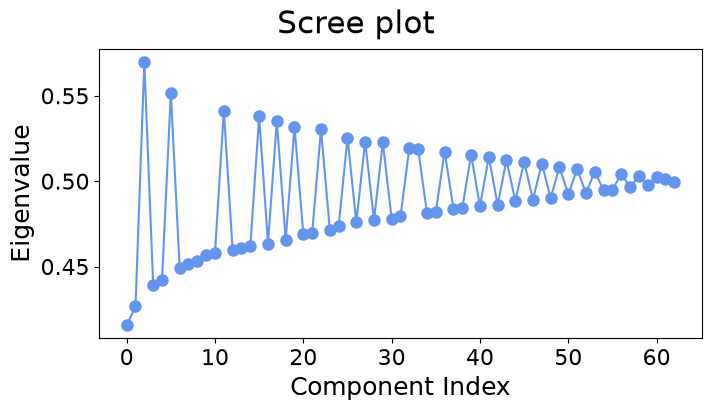

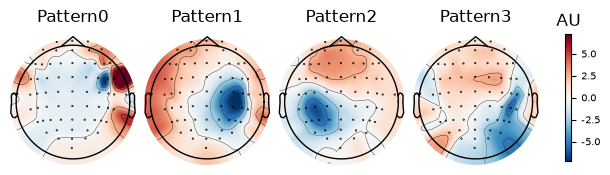

In [10]:
csp.fit_transform(X, y)
spf = get_spatial_filter_from_estimator(csp, info=epochs.info)
spf.plot_scree()
_ = spf.plot_patterns(components=np.arange(4))

#### Interpret the CSP figures

The scree plot and scalp patterns describe the CSP fit on all screened trials. They show which spatial signals the model emphasizes, but do not validate physiological activation. The four displayed patterns correspond to the model's four CSP components.